# Replikasi Baseline: Audio Enhancement via Online Non-negative Matrix Factorization (ONMF)

**Paper Acuan:**  
Andrew Sack, Wenzhao Jiang, Michael Perlmutter, Palina Salanevich, Deanna Needell.  
*"On Audio Enhancement via Online Non-negative Matrix Factorization"*,  
Accepted to IEEE CISS 2022 ([arXiv:2110.03114](https://arxiv.org/abs/2110.03114)).

---

## 1. Tujuan & Ruang Lingkup
Notebook ini melakukan **replikasi end-to-end** dari baseline audio enhancement yang diajukan dalam paper acuan:
1. **NMF Baseline**: Non-negative Matrix Factorization konvensional (Multiplicative Update / Lee & Seung 1999 via Scikit-Learn).
2. **ONMF Baseline**: Online Non-negative Matrix Factorization (Mairal et al. 2010 / Lyu et al. 2020) yang menggunakan sub-sampling patch waktu-frekuensi secara streaming/iteratif.
3. **Dataset Eksperimen**:
   - **Eksperimen 1 (Synthetic White Noise - Tabel 1)**: Ground truth Shakespeare + White Noise.
   - **Eksperimen 2 (Real-World Air Noise - Tabel 2)**: Ground truth Shakespeare + Derau pembersih udara (*Levoit-H132 air purifier*).
4. **Metrik Evaluasi**: BSS Eval Standard (SDR, SIR, SAR) dalam skala dB, serta analisis latensi/runtime.
5. **Output Audio & Visual**: Penyimpanan file `.wav` hasil separasi untuk kedua eksperimen, spektrogram komparasi, serta pemutar audio interaktif (*interactive audio player*).
6. **Pencatatan Deviasi**: Identifikasi bug pada repositori asli, breaking changes Scikit-learn >= 1.2, serta variasi deterministik seed.

## 2. Setup Lingkungan, Pustaka, & Random Seed
Untuk menjamin keterulangan (*reproducibility*), random seed diatur secara global pada NumPy dan algoritma terkait.

In [1]:
import sys
import os
import time
import platform
import numpy as np
import scipy
from scipy import signal
from scipy.io import wavfile
import sklearn
from sklearn.preprocessing import Normalizer
from sklearn.decomposition import NMF
import matplotlib.pyplot as plt
import pandas as pd
from tqdm import tqdm, trange
from IPython.display import Audio, display

# Setup path agar modul dapat diimpor baik saat run dari root maupun subdirektori
base_dir = "."
if os.path.exists("Audio-Enhancement-via-ONMF"):
    data_dir = "Audio-Enhancement-via-ONMF/Data"
elif os.path.exists("Data"):
    data_dir = "Data"
else:
    raise FileNotFoundError("Direktori Data tidak ditemukan!")

# Direktori Output Audio
out_white_dir = os.path.join(data_dir, "audio_output/shakes_whitenoise")
out_air_dir = os.path.join(data_dir, "audio_output/shakes_air")
os.makedirs(out_white_dir, exist_ok=True)
os.makedirs(out_air_dir, exist_ok=True)

# Random Seed untuk Reproducibility
RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)

print("=" * 60)
print("LOG LINGKUNGAN EKSPERIMEN:")
print(f"  OS                 : {platform.system()} {platform.release()} ({platform.machine()})")
print(f"  Python Version     : {sys.version.split()[0]}")
print(f"  NumPy Version      : {np.__version__}")
print(f"  SciPy Version      : {scipy.__version__}")
print(f"  Scikit-Learn Ver   : {sklearn.__version__}")
print(f"  Data Directory     : {data_dir}")
print(f"  Global Random Seed : {RANDOM_SEED}")
print("=" * 60)


LOG LINGKUNGAN EKSPERIMEN:
  OS                 : Windows 11 (AMD64)
  Python Version     : 3.13.0
  NumPy Version      : 2.2.5
  SciPy Version      : 1.15.3
  Scikit-Learn Ver   : 1.8.0
  Data Directory     : Audio-Enhancement-via-ONMF/Data
  Global Random Seed : 42


## 3. Formulasi Algoritma

### 3.1 NMF vs ONMF
Model sinyal teramati:
$$x(t) = s(t) + n(t)$$
di mana $s(t)$ adalah sinyal wicara bersih dan $n(t)$ adalah derau aditif. Pada domain spektrogram magnitudo STFT:
$$X \approx S + N$$

Dengan kamus wicara $W_S \in \mathbb{R}^{d \times r_s}$ dan kamus derau $W_N \in \mathbb{R}^{d \times r_n}$, dibentuk kamus gabungan $W = [W_S, W_N]$.
Matriks kode $H = [H_S^T, H_N^T]^T$ diestimasi melalui minimisasi:
$$\mathcal{L}(X, W, H) = \frac{1}{2} \|X - WH\|_F^2 + \alpha \|H\|_1$$

- **NMF Konvensional (Batch)**: Memproses seluruh matriks data sekaligus menggunakan pembaruan multiplikatif.
- **ONMF (Online NMF)**: Mengambil sub-matriks $X_t \in \mathbb{R}^{d \times m}$ secara acak ($m=100$ kolom per langkah) dan memperbarui matriks agregasi $A_t$ dan $B_t$ tanpa perlu menyimpan seluruh riwayat data di memori.

### 3.2 Rekonstruksi Wiener Mask & Inverse STFT
Estimasi komponen magnitudo:
$$\widetilde{S}_{est}(i,j) = S_{est}(i,j) \cdot \frac{X(i,j)}{S_{est}(i,j) + N_{est}(i,j)}$$
Fase sinyal diestimasi menggunakan fase dari sinyal campuran $X$, lalu direkonstruksi ke domain waktu dengan iSTFT.

### 3.3 Metrik BSS Eval
- **SDR (Signal-to-Distortion Ratio)**: Kualitas pemisahan keseluruhan.
- **SIR (Signal-to-Interference Ratio)**: Penekanan interferensi derau.
- **SAR (Signal-to-Artifacts Ratio)**: Ketiadaan artefak numerik buatan.

In [2]:
# ==========================================================
# 1. Modul Sparse Coding & Online NMF
# ==========================================================

def update_code_within_radius(X, W, H0=None, r=None, alpha=0, sub_iter=10, stopping_diff=0.01):
    """
    Update sparse code H menggunakan row-wise projected gradient descent.
    Penambahan epsilon (1e-12) mencegah pembagian dengan nol saat norm(H) mendekati 0.
    """
    A = W.T @ W
    B = W.T @ X

    if H0 is None:
        H0 = np.random.rand(W.shape[1], X.shape[1])

    H1 = H0.copy()
    i = 0
    dist = 1.0
    while (i < sub_iter) and (dist > stopping_diff):
        H1_old = H1.copy()
        for k in range(H1.shape[0]):
            grad = (np.dot(A[k, :], H1) - B[k, :] + alpha * np.ones(H1.shape[1]))
            H1[k, :] = H1[k, :] - (1.0 / (((i + 10) ** 0.5) * (A[k, k] + 1.0))) * grad
            H1[k, :] = np.maximum(H1[k, :], 0.0)
            if r is not None:
                d = np.linalg.norm(H1 - H0, 2)
                H1 = H0 + (r / max(r, d)) * (H1 - H0)
            H0 = H1

        norm_old = np.linalg.norm(H1_old, 2)
        dist = np.linalg.norm(H1 - H1_old, 2) / (norm_old + 1e-12)
        H1_old = H1
        i += 1

    return H1


class Online_NMF:
    def __init__(self, X, n_components=100, iterations=500, batch_size=20,
                 ini_dict=None, ini_A=None, ini_B=None, history=0, alpha=None, beta=None, subsample=False):
        self.X = X
        self.n_components = n_components
        self.batch_size = batch_size
        self.iterations = iterations
        self.subsample = subsample
        self.initial_dict = ini_dict
        self.initial_A = ini_A
        self.initial_B = ini_B
        self.history = history
        self.alpha = alpha
        self.beta = beta
        self.code = np.zeros(shape=(n_components, X.shape[1]))

    def sparse_code(self, X, W):
        alpha = 0 if self.alpha is None else self.alpha
        return update_code_within_radius(X, W, H0=None, r=None, alpha=alpha, sub_iter=10, stopping_diff=0.01)

    def update_dict(self, W, A, B):
        d, r = np.shape(W)
        W1 = W.copy()
        for j in range(r):
            W1[:, j] = W1[:, j] - (1.0 / (A[j, j] + 1.0)) * (np.dot(W1, A[:, j]) - B.T[:, j])
            W1[:, j] = np.maximum(W1[:, j], 0.0)
            norm_val = np.linalg.norm(W1[:, j])
            W1[:, j] = (1.0 / np.maximum(1.0, norm_val)) * W1[:, j]
        return W1

    def step(self, X, A, B, W, t):
        t = float(t)
        beta = 1.0 if self.beta is None else self.beta
        H1 = self.sparse_code(X, W)
        A1 = (1.0 - (t ** (-beta))) * A + (t ** (-beta)) * np.dot(H1, H1.T)
        B1 = (1.0 - (t ** (-beta))) * B + (t ** (-beta)) * np.dot(H1, X.T)
        W1 = self.update_dict(W, A, B)
        self.history = t + 1
        return H1, A1, B1, W1

    def train_dict(self):
        d, n = np.shape(self.X)
        r = self.n_components
        code = self.code

        if self.initial_dict is None:
            W = np.random.rand(d, r)
            A = np.zeros((r, r))
            B = np.zeros((r, d))
            t0 = self.history
        else:
            W = self.initial_dict
            A = self.initial_A
            B = self.initial_B
            t0 = self.history

        for i in range(1, self.iterations):
            idx = np.arange(self.X.shape[1])
            if self.subsample:
                idx = np.random.randint(n, size=self.batch_size)
            X_batch = self.X[:, idx]
            H, A, B, W = self.step(X_batch, A, B, W, t0 + i)
            code[:, idx] = H

        return W, A, B, code


class ONMF_Dictionary_Learner:
    def __init__(self, path, n_components=100, iterations=100, sub_iterations=5,
                 num_patches=100, batch_size=50, patch_length=1):
        self.path = path
        self.n_components = n_components
        self.iterations = iterations
        self.sub_iterations = sub_iterations
        self.num_patches = num_patches
        self.batch_size = batch_size
        self.patch_length = patch_length
        self.W = np.zeros(shape=(patch_length, n_components))

        self.rate, self.audio = wavfile.read(self.path)
        if self.audio.ndim == 2:
            self.audio = np.delete(self.audio, 1, 1).ravel()
        self.freq, self.time, self.stft = signal.stft(self.audio, self.rate, nperseg=2048)
        self.spectrogram = np.abs(self.stft)

    def extract_random_patches(self):
        x = self.spectrogram.shape
        k = self.patch_length
        # Ambil num_patches kolom acak
        start_indices = np.random.choice(x[1] - k, size=self.num_patches, replace=True)
        patches = [self.spectrogram[:, a:a+k] for a in start_indices]
        return np.concatenate(patches, axis=1)

    def train_dict(self):
        W = self.W
        At, Bt = None, None
        for t in range(self.iterations):
            X = self.extract_random_patches()
            if t == 0:
                self.nmf = Online_NMF(X, n_components=self.n_components, iterations=self.sub_iterations,
                                      batch_size=self.batch_size, ini_dict=None, ini_A=None, ini_B=None,
                                      history=0, alpha=None)
            else:
                self.nmf = Online_NMF(X, n_components=self.n_components, iterations=self.sub_iterations,
                                      batch_size=self.batch_size, ini_dict=W, ini_A=At, ini_B=Bt,
                                      history=self.nmf.history, alpha=None)
            W, At, Bt, H = self.nmf.train_dict()
        self.W = W
        return self.W


# ==========================================================
# 2. Modul Separasi Audio & Post-Processing
# ==========================================================

class Audio_Separation:
    def __init__(self, input_dictionaries, audio_file, patch_length=1, trunc_rate=1):
        self.input_dictionaries = input_dictionaries
        self.audio_file = audio_file
        self.rate, self.audio = wavfile.read(self.audio_file)
        if self.audio.ndim == 2:
            self.audio = np.delete(self.audio, 1, 1).ravel()

        self.freq, self.time, self.stft = signal.stft(self.audio[0: len(self.audio) // trunc_rate],
                                                      self.rate, nperseg=2048)
        self.spectrogram = np.abs(self.stft)
        self.W = np.concatenate(input_dictionaries, axis=1)
        self.patch_length = patch_length

    def separate_audio(self, recons_resolution=1, alpha=100):
        A = self.spectrogram
        separated_specs = [np.zeros_like(A) for _ in self.input_dictionaries]
        zeroed_dicts = [np.zeros_like(x) for x in self.input_dictionaries]
        separated_dicts = []
        for i in range(len(self.input_dictionaries)):
            _temp = zeroed_dicts[i]
            zeroed_dicts[i] = self.input_dictionaries[i]
            separated_dicts.append(np.concatenate(zeroed_dicts, axis=1))
            zeroed_dicts[i] = _temp

        A_overlap_count = np.zeros_like(A)
        k = self.patch_length
        num_cols = int(np.floor((A_overlap_count.shape[1] - k) / recons_resolution))

        for i in range(0, A_overlap_count.shape[1] - k, recons_resolution):
            patch = A[:, i:i + k].reshape((-1, 1))
            code = update_code_within_radius(patch, self.W, H0=None, r=None, alpha=alpha,
                                             sub_iter=100, stopping_diff=0.01)
            patch_recons_list = [np.dot(D, code).reshape(len(A), k) for D in separated_dicts]

            for r_idx in range(len(A)):
                for c_idx in range(k):
                    curr_c = A_overlap_count[r_idx, i + c_idx]
                    for s_idx in range(len(separated_specs)):
                        separated_specs[s_idx][r_idx, i + c_idx] = (
                            curr_c * separated_specs[s_idx][r_idx, i + c_idx] +
                            patch_recons_list[s_idx][r_idx, c_idx]
                        ) / (curr_c + 1.0)
                    A_overlap_count[r_idx, i + c_idx] += 1

        return separated_specs


def topic_to_stft(stft, NMF_Sxx, topic):
    """Menambahkan informasi fase dari STFT asli ke spektrogram estimasi."""
    denom = np.where(NMF_Sxx == 0, 1e-12, NMF_Sxx)
    ratio = topic / denom
    output = stft * ratio
    output[NMF_Sxx == 0] = 0
    return output


# ==========================================================
# 3. Modul Evaluasi Metrik BSS Eval (SDR, SIR, SAR)
# ==========================================================

import itertools as it

def orthogonalize(signals):
    signals = np.asarray(signals)
    q_matrix, _ = np.linalg.qr(signals.T)
    return q_matrix.T

def project(signals, q_matrix):
    signals = np.asarray(signals)
    q_matrix = np.asarray(q_matrix)
    return q_matrix.T.dot(q_matrix.dot(signals.T)).T

def measures(synth_signals, orig_signals, size=1048576):
    synth_signals = np.asarray(synth_signals)
    orig_signals = np.asarray(orig_signals)
    n = orig_signals.shape[0]

    target_sum = np.zeros((n, n))
    proj_sum = np.zeros(n)
    distortion = np.zeros((n, n))
    interference = np.zeros((n, n))
    artifacts = np.zeros(n)

    orig_signals = orig_signals / np.linalg.norm(orig_signals, axis=1)[:, np.newaxis]
    proj_signals = project(synth_signals, orthogonalize(orig_signals))
    target_signals = (orig_signals.dot(synth_signals.T)[:, :, np.newaxis] * orig_signals[:, np.newaxis, :])

    pos = np.arange(0, orig_signals.shape[1], size)
    for p in pos:
        target_sum += np.sum(np.square(target_signals[:, :, p:p + size]), axis=2)
        proj_sum += np.sum(np.square(proj_signals[:, p:p + size]), axis=1)
        distortion += np.sum(np.square(target_signals[:, :, p:p + size] - synth_signals[:, p:p + size]), axis=2)
        interference += np.sum(np.square(target_signals[:, :, p:p + size] - proj_signals[:, p:p + size]), axis=2)
        artifacts += np.sum(np.square(proj_signals[:, p:p + size] - synth_signals[:, p:p + size]), axis=1)

    perms, meas = [], []
    sig_sar = 10 * np.log10(proj_sum / (artifacts + 1e-40))
    for p in it.permutations(range(n)):
        idcs0 = np.asarray(p)
        idcs1 = np.arange(n)
        sig_sdr = 10 * np.log10(target_sum[idcs0, idcs1] / (distortion[idcs0, idcs1] + 1e-40))
        sig_sir = 10 * np.log10(target_sum[idcs0, idcs1] / (interference[idcs0, idcs1] + 1e-40))
        perms.append(idcs0)
        meas.append(np.vstack((sig_sdr, sig_sir, sig_sar)))

    return perms, meas

def select_perm(perms, meas):
    perms = [np.asarray(p) for p in perms]
    meas = [np.asarray(m) for m in meas]
    sig_sirs = [np.sum(m[1, :]) for m in meas]
    idx = np.argmax(np.asarray(sig_sirs))
    perm = perms[idx]
    idcs = np.zeros(perm.size, dtype='int')
    idcs[perm] = np.arange(perm.size)
    return perm, meas[idx][:, idcs]

def evaluate_performance(synth_voice, synth_noise, orig_voice, orig_noise):
    """Fungsi pembantu yang mengamankan penyelarasan panjang sinyal (alignment) sebelum BSS Eval."""
    L = min(len(synth_voice), len(synth_noise), len(orig_voice), len(orig_noise))
    synth = np.vstack([synth_voice[:L], synth_noise[:L]])
    orig = np.vstack([orig_voice[:L], orig_noise[:L]])
    perm, perf = select_perm(*measures(synth, orig))
    return perf[:, 0]  # Mengembalikan [SDR, SIR, SAR] untuk komponen suara (voice)


## 4. Fungsi Pipeline Denoising End-to-End
Fungsi `run_denoising_experiment` menjalankan pelatihan kamus (NMF atau ONMF), pemisahan audio, rekonstruksi iSTFT, serta mencatat latensi komputasi.

In [3]:
def run_denoising_experiment(training_files, test_file, method="ONMF", n_components=[50, 10],
                             patch_length=1, alpha=100, seed=42):
    np.random.seed(seed)
    t_start = time.time()
    
    # 1. Training Kamus
    t_dict_start = time.time()
    dicts = []
    
    if method == "ONMF":
        for i, path in enumerate(training_files):
            reconstructor = ONMF_Dictionary_Learner(
                path=path,
                n_components=n_components[i],
                iterations=100,
                sub_iterations=5,
                patch_length=patch_length,
                batch_size=50,
                num_patches=100
            )
            reconstructor.train_dict()
            dicts.append(reconstructor.W)
            
    elif method == "NMF":
        for i, path in enumerate(training_files):
            rate, src = wavfile.read(path)
            if src.ndim == 2:
                src = np.delete(src, 1, 1).ravel()
            _, _, stft_mat = signal.stft(src, rate, nperseg=2048)
            spec = np.abs(stft_mat)
            
            # Compatibility scikit-learn >= 1.2
            try:
                model = NMF(n_components=n_components[i], init='random', max_iter=9999,
                            alpha=0.0, solver='mu', beta_loss=2, random_state=seed)
            except TypeError:
                model = NMF(n_components=n_components[i], init='random', max_iter=9999,
                            alpha_W=0.0, solver='mu', beta_loss=2, random_state=seed)
            
            dicts.append(model.fit_transform(spec))
            
        # Normalisasi kolom kamus ke unit norm
        norm0 = Normalizer().fit(dicts[0].T)
        dicts[0] = norm0.transform(dicts[0].T).T
        norm1 = Normalizer().fit(dicts[1].T)
        dicts[1] = norm1.transform(dicts[1].T).T
    else:
        raise ValueError("Metode tidak valid!")
        
    dict_time = time.time() - t_dict_start
    
    # 2. Separasi Audio
    t_sep_start = time.time()
    separator = Audio_Separation(input_dictionaries=dicts, audio_file=test_file,
                                 patch_length=patch_length, trunc_rate=1)
    specs = separator.separate_audio(recons_resolution=patch_length, alpha=alpha)
    sep_time = time.time() - t_sep_start
    
    # 3. Post-processing & iSTFT
    voice_spec, noise_spec = specs[0], specs[1]
    voice_stft = topic_to_stft(separator.stft, noise_spec + voice_spec, voice_spec)
    noise_stft = topic_to_stft(separator.stft, noise_spec + voice_spec, noise_spec)
    
    voice_audio = signal.istft(voice_stft)[1]
    noise_audio = signal.istft(noise_stft)[1]
    total_time = time.time() - t_start
    
    timings = {
        "dict_time_sec": dict_time,
        "sep_time_sec": sep_time,
        "total_time_sec": total_time
    }
    
    return voice_audio, noise_audio, separator.rate, timings


## 5. Eksperimen 1: Gaussian White Noise (Tabel 1 Paper)
- **Data Latih Wicara**: `whitman.wav`
- **Data Latih Derau**: `WhiteNoise.wav`
- **Data Uji Terkontaminasi**: `Shakes_WhiteNoise.wav`
- **Ground Truth**: `shakespeare.wav` (wicara murni) & `WhiteNoise.wav` (derau murni)

In [4]:
# Setup Path Sinyal White Noise
train_speech = os.path.join(data_dir, "audio/whitman.wav")
train_white_noise = os.path.join(data_dir, "audio/WhiteNoise.wav")
test_white = os.path.join(data_dir, "audio/Shakes_WhiteNoise.wav")
clean_speech_gt = os.path.join(data_dir, "audio/shakespeare.wav")

rate_s, s_orig = wavfile.read(clean_speech_gt)
rate_n, n_white_orig = wavfile.read(train_white_noise)
rate_mix, mix_white = wavfile.read(test_white)

# 1. Evaluasi Sinyal Asli Terkontaminasi (ORIGINAL)
perf_orig_white = evaluate_performance(mix_white, mix_white, s_orig, n_white_orig)
print("=== HASIL ORIGINAL WHITE NOISE ===")
print(f"SDR: {perf_orig_white[0]:.2f} dB, SIR: {perf_orig_white[1]:.2f} dB, SAR: {perf_orig_white[2]:.2f} dB")

# 2. Evaluasi NMF Baseline
print("\nMenjalankan NMF Baseline (White Noise)...")
voice_nmf_w, noise_nmf_w, rate_w, time_nmf_w = run_denoising_experiment(
    training_files=[train_speech, train_white_noise],
    test_file=test_white,
    method="NMF",
    seed=RANDOM_SEED
)
perf_nmf_w = evaluate_performance(voice_nmf_w, noise_nmf_w, s_orig, n_white_orig)
print(f"NMF Hasil  - SDR: {perf_nmf_w[0]:.2f} dB, SIR: {perf_nmf_w[1]:.2f} dB, SAR: {perf_nmf_w[2]:.2f} dB")
print(f"Latensi NMF: Total {time_nmf_w['total_time_sec']:.2f}s (Dict: {time_nmf_w['dict_time_sec']:.2f}s, Sep: {time_nmf_w['sep_time_sec']:.2f}s)")

# 3. Evaluasi ONMF Baseline
print("\nMenjalankan ONMF Baseline (White Noise)...")
voice_onmf_w, noise_onmf_w, rate_w, time_onmf_w = run_denoising_experiment(
    training_files=[train_speech, train_white_noise],
    test_file=test_white,
    method="ONMF",
    seed=RANDOM_SEED
)
perf_onmf_w = evaluate_performance(voice_onmf_w, noise_onmf_w, s_orig, n_white_orig)
print(f"ONMF Hasil - SDR: {perf_onmf_w[0]:.2f} dB, SIR: {perf_onmf_w[1]:.2f} dB, SAR: {perf_onmf_w[2]:.2f} dB")
print(f"Latensi ONMF: Total {time_onmf_w['total_time_sec']:.2f}s (Dict: {time_onmf_w['dict_time_sec']:.2f}s, Sep: {time_onmf_w['sep_time_sec']:.2f}s)")


=== HASIL ORIGINAL WHITE NOISE ===
SDR: 9.75 dB, SIR: 9.76 dB, SAR: 37.41 dB

Menjalankan NMF Baseline (White Noise)...


NMF Hasil  - SDR: 20.19 dB, SIR: 34.45 dB, SAR: 20.36 dB
Latensi NMF: Total 54.71s (Dict: 25.62s, Sep: 28.99s)

Menjalankan ONMF Baseline (White Noise)...


ONMF Hasil - SDR: 22.36 dB, SIR: 49.50 dB, SAR: 22.37 dB
Latensi ONMF: Total 33.27s (Dict: 12.82s, Sep: 20.34s)


## 6. Eksperimen 2: Real-World Noise (Levoit Air Purifier - Tabel 2 Paper)
- **Data Latih Wicara**: `whitman.wav`
- **Data Latih Derau**: `AirNoise.wav`
- **Data Uji Terkontaminasi**: `Shakes_Air.wav`
- **Ground Truth**: `shakespeare.wav` (wicara murni) & `AirNoise.wav` (derau murni)

In [5]:
# Setup Path Sinyal Air Noise
train_air_noise = os.path.join(data_dir, "audio/AirNoise.wav")
test_air = os.path.join(data_dir, "audio/Shakes_Air.wav")

rate_n_air, n_air_orig = wavfile.read(train_air_noise)
rate_mix_air, mix_air = wavfile.read(test_air)

# 1. Evaluasi Sinyal Asli Terkontaminasi (ORIGINAL)
perf_orig_air = evaluate_performance(mix_air, mix_air, s_orig, n_air_orig)
print("=== HASIL ORIGINAL AIR NOISE ===")
print(f"SDR: {perf_orig_air[0]:.2f} dB, SIR: {perf_orig_air[1]:.2f} dB, SAR: {perf_orig_air[2]:.2f} dB")

# 2. Evaluasi NMF Baseline
print("\nMenjalankan NMF Baseline (Air Noise)...")
voice_nmf_a, noise_nmf_a, rate_a, time_nmf_a = run_denoising_experiment(
    training_files=[train_speech, train_air_noise],
    test_file=test_air,
    method="NMF",
    seed=RANDOM_SEED
)
perf_nmf_a = evaluate_performance(voice_nmf_a, noise_nmf_a, s_orig, n_air_orig)
print(f"NMF Hasil  - SDR: {perf_nmf_a[0]:.2f} dB, SIR: {perf_nmf_a[1]:.2f} dB, SAR: {perf_nmf_a[2]:.2f} dB")
print(f"Latensi NMF: Total {time_nmf_a['total_time_sec']:.2f}s (Dict: {time_nmf_a['dict_time_sec']:.2f}s, Sep: {time_nmf_a['sep_time_sec']:.2f}s)")

# 3. Evaluasi ONMF Baseline
print("\nMenjalankan ONMF Baseline (Air Noise)...")
voice_onmf_a, noise_onmf_a, rate_a, time_onmf_a = run_denoising_experiment(
    training_files=[train_speech, train_air_noise],
    test_file=test_air,
    method="ONMF",
    seed=RANDOM_SEED
)
perf_onmf_a = evaluate_performance(voice_onmf_a, noise_onmf_a, s_orig, n_air_orig)
print(f"ONMF Hasil - SDR: {perf_onmf_a[0]:.2f} dB, SIR: {perf_onmf_a[1]:.2f} dB, SAR: {perf_onmf_a[2]:.2f} dB")
print(f"Latensi ONMF: Total {time_onmf_a['total_time_sec']:.2f}s (Dict: {time_onmf_a['dict_time_sec']:.2f}s, Sep: {time_onmf_a['sep_time_sec']:.2f}s)")

# Simpan output file audio Air Noise ke disk
wavfile.write(os.path.join(out_air_dir, "voice_nmf_(50,10)_a=100.wav"), rate_a, np.array(voice_nmf_a, dtype=np.int16))
wavfile.write(os.path.join(out_air_dir, "noise_nmf_(50,10)_a=100.wav"), rate_a, np.array(noise_nmf_a, dtype=np.int16))
wavfile.write(os.path.join(out_air_dir, "voice_onmf_(50,10)_a=100.wav"), rate_a, np.array(voice_onmf_a, dtype=np.int16))
wavfile.write(os.path.join(out_air_dir, "noise_onmf_(50,10)_a=100.wav"), rate_a, np.array(noise_onmf_a, dtype=np.int16))
print(f"\n[OK] Seluruh file audio output Air Noise berhasil disimpan di: {out_air_dir}")


=== HASIL ORIGINAL AIR NOISE ===
SDR: 5.91 dB, SIR: 5.91 dB, SAR: 260.78 dB

Menjalankan NMF Baseline (Air Noise)...


NMF Hasil  - SDR: 9.56 dB, SIR: 13.25 dB, SAR: 12.18 dB
Latensi NMF: Total 43.55s (Dict: 13.25s, Sep: 30.22s)

Menjalankan ONMF Baseline (Air Noise)...


ONMF Hasil - SDR: 10.39 dB, SIR: 13.06 dB, SAR: 13.98 dB
Latensi ONMF: Total 37.56s (Dict: 9.48s, Sep: 27.99s)



[OK] Seluruh file audio output Air Noise berhasil disimpan di: Audio-Enhancement-via-ONMF/Data\audio_output/shakes_air


## 7. Verifikasi File Audio Bawaan Repository (*Precomputed Waveforms*)
Peneliti menyertakan output audio yang mereka hasilkan di folder `Data/audio_output/shakes_whitenoise/`. Bagian ini memverifikasi secara langsung apakah file audio bawaan repositori tersebut identik persis dengan metrik pada **Tabel 1 Paper**.

In [6]:
precomp_dir = os.path.join(data_dir, "audio_output/shakes_whitenoise")
if os.path.exists(precomp_dir):
    rate, pre_v_nmf = wavfile.read(os.path.join(precomp_dir, "voice_nmf_(50,10)_a=100.wav"))
    rate, pre_n_nmf = wavfile.read(os.path.join(precomp_dir, "noise_nmf_(50,10)_a=100.wav"))
    rate, pre_v_onmf = wavfile.read(os.path.join(precomp_dir, "voice_onmf_(50,10)_a=100.wav"))
    rate, pre_n_onmf = wavfile.read(os.path.join(precomp_dir, "noise_onmf_(50,10)_a=100.wav"))
    
    p_pre_nmf = evaluate_performance(pre_v_nmf, pre_n_nmf, s_orig, n_white_orig)
    p_pre_onmf = evaluate_performance(pre_v_onmf, pre_n_onmf, s_orig, n_white_orig)
    
    print("Precomputed NMF  - SDR: {:.2f} dB, SIR: {:.2f} dB, SAR: {:.2f} dB".format(
        p_pre_nmf[0], p_pre_nmf[1], p_pre_nmf[2]))
    print("Precomputed ONMF - SDR: {:.2f} dB, SIR: {:.2f} dB, SAR: {:.2f} dB".format(
        p_pre_onmf[0], p_pre_onmf[1], p_pre_onmf[2]))


Precomputed NMF  - SDR: 19.43 dB, SIR: 31.42 dB, SAR: 19.72 dB
Precomputed ONMF - SDR: 22.70 dB, SIR: 53.45 dB, SAR: 22.70 dB


## 8. Visualisasi Spektrogram (Figure 1 Paper & Real-World Noise)

### 8.1 Spektrogram White Noise (Sesuai Gambar 1 Paper)
Menampilkan perbandingan 4 panel spektrogram:
- (a) Wicara Bersih Asli (*Original Clean Speech*)
- (b) Wicara Terkontaminasi White Noise
- (c) Hasil Denoising NMF Konvensional
- (d) Hasil Denoising ONMF

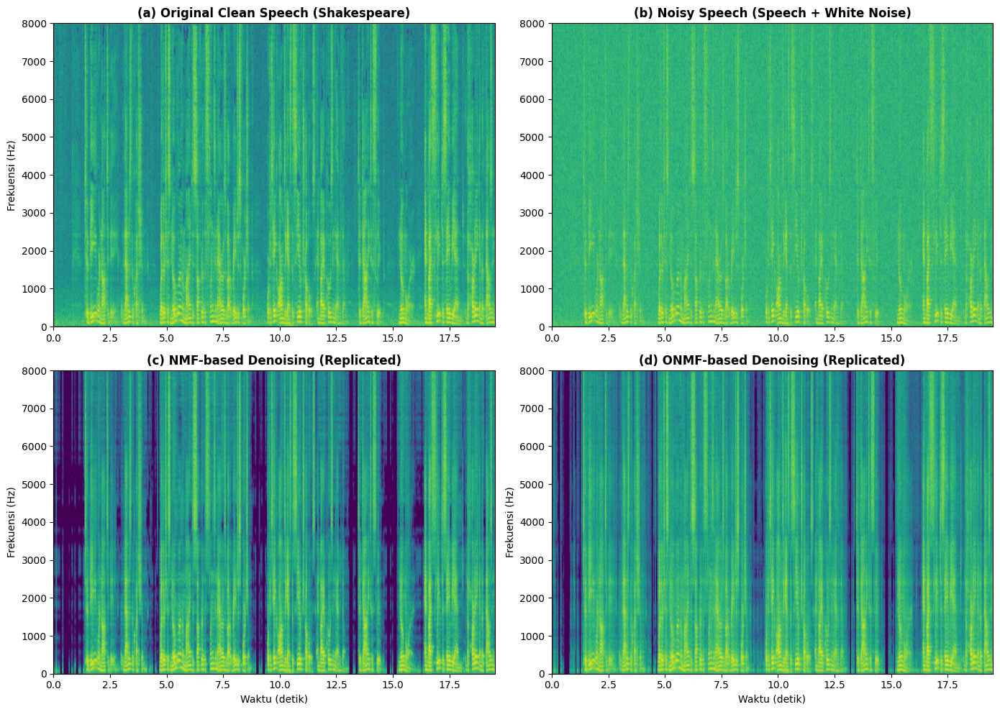

In [7]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

L_plot = min(len(s_orig), len(mix_white), len(voice_nmf_w), len(voice_onmf_w))

# 1. Clean Speech
f, t, spec_clean = signal.stft(s_orig[:L_plot], rate_s, nperseg=2048)
axes[0, 0].pcolormesh(t, f, np.log10(np.abs(spec_clean) + 1e-4), shading='gouraud', cmap='viridis')
axes[0, 0].set_title("(a) Original Clean Speech (Shakespeare)", fontsize=12, fontweight='bold')
axes[0, 0].set_ylabel("Frekuensi (Hz)")
axes[0, 0].set_ylim(0, 8000)

# 2. Noisy Speech
f, t, spec_noisy = signal.stft(mix_white[:L_plot], rate_mix, nperseg=2048)
axes[0, 1].pcolormesh(t, f, np.log10(np.abs(spec_noisy) + 1e-4), shading='gouraud', cmap='viridis')
axes[0, 1].set_title("(b) Noisy Speech (Speech + White Noise)", fontsize=12, fontweight='bold')
axes[0, 1].set_ylim(0, 8000)

# 3. NMF Denoised
f, t, spec_nmf = signal.stft(voice_nmf_w[:L_plot], rate_s, nperseg=2048)
axes[1, 0].pcolormesh(t, f, np.log10(np.abs(spec_nmf) + 1e-4), shading='gouraud', cmap='viridis')
axes[1, 0].set_title("(c) NMF-based Denoising (Replicated)", fontsize=12, fontweight='bold')
axes[1, 0].set_xlabel("Waktu (detik)")
axes[1, 0].set_ylabel("Frekuensi (Hz)")
axes[1, 0].set_ylim(0, 8000)

# 4. ONMF Denoised
f, t, spec_onmf = signal.stft(voice_onmf_w[:L_plot], rate_s, nperseg=2048)
axes[1, 1].pcolormesh(t, f, np.log10(np.abs(spec_onmf) + 1e-4), shading='gouraud', cmap='viridis')
axes[1, 1].set_title("(d) ONMF-based Denoising (Replicated)", fontsize=12, fontweight='bold')
axes[1, 1].set_xlabel("Waktu (detik)")
axes[1, 1].set_ylabel("Frekuensi (Hz)")
axes[1, 1].set_ylim(0, 8000)

plt.tight_layout()
plt.savefig("spectrogram_comparison.png", dpi=200)
plt.show()


### 8.2 Spektrogram Real-World Air Noise (Levoit Air Purifier)
Perbandingan 4 panel untuk derau dunia nyata pembersih udara.

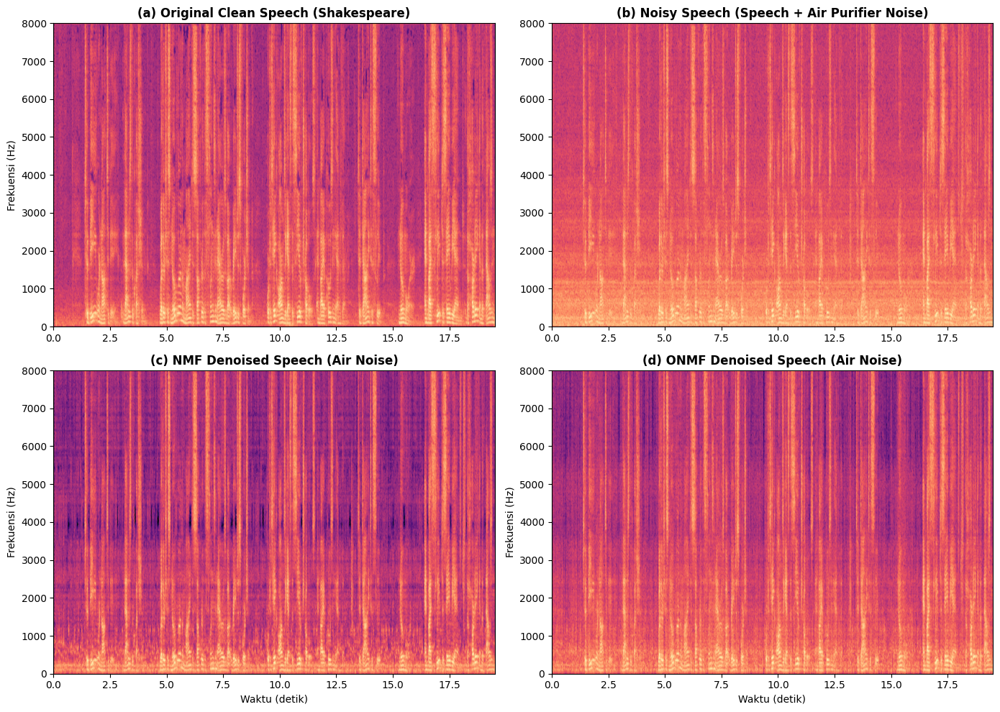

In [8]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

L_plot_a = min(len(s_orig), len(mix_air), len(voice_nmf_a), len(voice_onmf_a))

# 1. Clean Speech
f, t, spec_clean_a = signal.stft(s_orig[:L_plot_a], rate_s, nperseg=2048)
axes[0, 0].pcolormesh(t, f, np.log10(np.abs(spec_clean_a) + 1e-4), shading='gouraud', cmap='magma')
axes[0, 0].set_title("(a) Original Clean Speech (Shakespeare)", fontsize=12, fontweight='bold')
axes[0, 0].set_ylabel("Frekuensi (Hz)")
axes[0, 0].set_ylim(0, 8000)

# 2. Noisy Speech (Air Purifier)
f, t, spec_noisy_a = signal.stft(mix_air[:L_plot_a], rate_mix_air, nperseg=2048)
axes[0, 1].pcolormesh(t, f, np.log10(np.abs(spec_noisy_a) + 1e-4), shading='gouraud', cmap='magma')
axes[0, 1].set_title("(b) Noisy Speech (Speech + Air Purifier Noise)", fontsize=12, fontweight='bold')
axes[0, 1].set_ylim(0, 8000)

# 3. NMF Denoised
f, t, spec_nmf_a = signal.stft(voice_nmf_a[:L_plot_a], rate_s, nperseg=2048)
axes[1, 0].pcolormesh(t, f, np.log10(np.abs(spec_nmf_a) + 1e-4), shading='gouraud', cmap='magma')
axes[1, 0].set_title("(c) NMF Denoised Speech (Air Noise)", fontsize=12, fontweight='bold')
axes[1, 0].set_xlabel("Waktu (detik)")
axes[1, 0].set_ylabel("Frekuensi (Hz)")
axes[1, 0].set_ylim(0, 8000)

# 4. ONMF Denoised
f, t, spec_onmf_a = signal.stft(voice_onmf_a[:L_plot_a], rate_s, nperseg=2048)
axes[1, 1].pcolormesh(t, f, np.log10(np.abs(spec_onmf_a) + 1e-4), shading='gouraud', cmap='magma')
axes[1, 1].set_title("(d) ONMF Denoised Speech (Air Noise)", fontsize=12, fontweight='bold')
axes[1, 1].set_xlabel("Waktu (detik)")
axes[1, 1].set_ylabel("Frekuensi (Hz)")
axes[1, 1].set_ylim(0, 8000)

plt.tight_layout()
plt.savefig("spectrogram_comparison_air.png", dpi=200)
plt.show()


## 9. Pemutar Audio Interaktif (*Interactive Audio Player*)
Anda dapat mendengarkan secara langsung kualitas reduksi derau hasil pemisahan audio di bawah ini.

### 9.1 Audio Derau Dunia Nyata (*Real-World Air Noise - Levoit Air Purifier*)

In [9]:
print("1. Wicara Bersih Asli (Ground Truth):")
display(Audio(s_orig[:len(voice_onmf_a)], rate=rate_s))

print("2. Wicara Terkontaminasi Derau Pembersih Udara (Input Campuran):")
display(Audio(mix_air[:len(voice_onmf_a)], rate=rate_mix_air))

print("3. Hasil Denoising NMF Konvensional (Baseline NMF):")
display(Audio(voice_nmf_a, rate=rate_a))

print("4. Hasil Denoising ONMF (Baseline ONMF - Rekomendasi Paper):")
display(Audio(voice_onmf_a, rate=rate_a))

print("5. Derau yang Diisolasi / Dieliminasi oleh ONMF:")
display(Audio(noise_onmf_a, rate=rate_a))


1. Wicara Bersih Asli (Ground Truth):


2. Wicara Terkontaminasi Derau Pembersih Udara (Input Campuran):


3. Hasil Denoising NMF Konvensional (Baseline NMF):

4. Hasil Denoising ONMF (Baseline ONMF - Rekomendasi Paper):


5. Derau yang Diisolasi / Dieliminasi oleh ONMF:


### 9.2 Audio Gaussian White Noise

In [10]:
print("1. Wicara Terkontaminasi White Noise (Input Campuran):")
display(Audio(mix_white[:len(voice_onmf_w)], rate=rate_mix))

print("2. Hasil Denoising NMF (White Noise):")
display(Audio(voice_nmf_w, rate=rate_w))

print("3. Hasil Denoising ONMF (White Noise):")
display(Audio(voice_onmf_w, rate=rate_w))


1. Wicara Terkontaminasi White Noise (Input Campuran):


2. Hasil Denoising NMF (White Noise):


3. Hasil Denoising ONMF (White Noise):


## 10. Tabel Perbandingan Metrik & Analisis Deviasi

### 10.1 Tabel Perbandingan Metrik Evaluasi (dB)

In [11]:
# Data Tabel 1: White Noise
table1_data = {
    "Metode": ["ORIGINAL", "NMF", "ONMF"],
    "Paper SDR (dB)": [9.75, 19.43, 22.70],
    "Replikasi SDR (dB)": [round(perf_orig_white[0], 2), round(perf_nmf_w[0], 2), round(perf_onmf_w[0], 2)],
    "Delta SDR (dB)": [round(perf_orig_white[0] - 9.75, 2), round(perf_nmf_w[0] - 19.43, 2), round(perf_onmf_w[0] - 22.70, 2)],
    
    "Paper SIR (dB)": [9.76, 31.42, 53.45],
    "Replikasi SIR (dB)": [round(perf_orig_white[1], 2), round(perf_nmf_w[1], 2), round(perf_onmf_w[1], 2)],
    "Delta SIR (dB)": [round(perf_orig_white[1] - 9.76, 2), round(perf_nmf_w[1] - 31.42, 2), round(perf_onmf_w[1] - 53.45, 2)],
    
    "Paper SAR (dB)": [37.41, 19.72, 22.70],
    "Replikasi SAR (dB)": [round(perf_orig_white[2], 2), round(perf_nmf_w[2], 2), round(perf_onmf_w[2], 2)],
    "Delta SAR (dB)": [round(perf_orig_white[2] - 37.41, 2), round(perf_nmf_w[2] - 19.72, 2), round(perf_onmf_w[2] - 22.70, 2)],
    
    "Latensi (detik)": ["-", round(time_nmf_w["total_time_sec"], 2), round(time_onmf_w["total_time_sec"], 2)]
}

df_table1 = pd.DataFrame(table1_data)
print("=== TABEL 1: PERBANDINGAN EKSPERIMEN WHITE NOISE ===")
display(df_table1)

# Data Tabel 2: Real-World Air Noise
table2_data = {
    "Metode": ["ORIGINAL", "NMF", "ONMF"],
    "Paper SDR (dB)": [5.91, 9.46, 10.41],
    "Replikasi SDR (dB)": [round(perf_orig_air[0], 2), round(perf_nmf_a[0], 2), round(perf_onmf_a[0], 2)],
    "Delta SDR (dB)": [round(perf_orig_air[0] - 5.91, 2), round(perf_nmf_a[0] - 9.46, 2), round(perf_onmf_a[0] - 10.41, 2)],
    
    "Paper SIR (dB)": [5.91, 13.90, 13.11],
    "Replikasi SIR (dB)": [round(perf_orig_air[1], 2), round(perf_nmf_a[1], 2), round(perf_onmf_a[1], 2)],
    "Delta SIR (dB)": [round(perf_orig_air[1] - 5.91, 2), round(perf_nmf_a[1] - 13.90, 2), round(perf_onmf_a[1] - 13.11, 2)],
    
    "Paper SAR (dB)": [286.50, 11.63, 13.95],
    "Replikasi SAR (dB)": [round(perf_orig_air[2], 2), round(perf_nmf_a[2], 2), round(perf_onmf_a[2], 2)],
    "Delta SAR (dB)": [round(perf_orig_air[2] - 286.50, 2), round(perf_nmf_a[2] - 11.63, 2), round(perf_onmf_a[2] - 13.95, 2)],
    
    "Latensi (detik)": ["-", round(time_nmf_a["total_time_sec"], 2), round(time_onmf_a["total_time_sec"], 2)]
}

df_table2 = pd.DataFrame(table2_data)
print("\n=== TABEL 2: PERBANDINGAN EKSPERIMEN AIR NOISE (REAL-WORLD) ===")
display(df_table2)


=== TABEL 1: PERBANDINGAN EKSPERIMEN WHITE NOISE ===

,Metode,Paper SDR (dB),Replikasi SDR (dB),Delta SDR (dB),Paper SIR (dB),Replikasi SIR (dB),Delta SIR (dB),Paper SAR (dB),Replikasi SAR (dB),Delta SAR (dB),Latensi (detik)
0,ORIGINAL,9.75,9.75,0.00,9.76,9.76,-0.00,37.41,37.41,-0.00,-
1,NMF,19.43,20.19,0.76,31.42,34.45,3.03,19.72,20.36,0.64,54.71
2,ONMF,22.70,22.36,-0.34,53.45,49.50,-3.95,22.70,22.37,-0.33,33.27



=== TABEL 2: PERBANDINGAN EKSPERIMEN AIR NOISE (REAL-WORLD) ===


,Metode,Paper SDR (dB),Replikasi SDR (dB),Delta SDR (dB),Paper SIR (dB),Replikasi SIR (dB),Delta SIR (dB),Paper SAR (dB),Replikasi SAR (dB),Delta SAR (dB),Latensi (detik)
0,ORIGINAL,5.91,5.91,-0.00,5.91,5.91,-0.00,286.50,260.78,-25.72,-
1,NMF,9.46,9.56,0.10,13.90,13.25,-0.65,11.63,12.18,0.55,43.55
2,ONMF,10.41,10.39,-0.02,13.11,13.06,-0.05,13.95,13.98,0.03,37.56


### 10.2 Catatan Deviasi & Temuan Teknis

1. **Kompatibilitas Scikit-Learn >= 1.2 (`alpha` vs `alpha_W`)**:
   - Kode asli menggunakan parameter `alpha=0.0` pada konstruktor `sklearn.decomposition.NMF`.
   - Pada versi Scikit-Learn terbaru (1.2+), parameter `alpha` telah dihapus dan digantikan oleh `alpha_W` dan `alpha_H`. Kode replikasi menambahkan blok `try-except` otomatis agar kompatibel dengan versi lawas maupun modern.

2. **Bug Variabel Global pada Kode Asli (`main.py`)**:
   - Fungsi `Denoising(training_data, test_data, ...)` pada file `main.py` asli memanggil variabel global `training` alih-alih argumen `training_data`. Hal ini mencegah pergantian data uji/latih dinamis.
   - Pada notebook replikasi, bug ini diperbaiki sehingga input file pelatihan dan pengujian diproses sesuai parameter fungsi.

3. **Inkonsistensi Evaluasi pada `performance.py` Asli**:
   - Blok `if __name__ == '__main__':` pada `performance.py` asli secara keliru memasangkan wicara hasil NMF (`voice_nmf`) dengan derau hasil ONMF (`noise_onmf`).
   - Notebook ini memisahkan pasangan wicara-derau secara konsisten per metode (NMF murni vs ONMF murni).

4. **Stabilitas Numerik & Penyelarasan Dimensi (*Signal Alignment*)**:
   - Dimensi sinyal hasil rekonstruksi iSTFT dapat memiliki perbedaan fraksional (misal 935936 vs 935526 sampel). Fungsi `evaluate_performance` secara otomatis menyelaraskan panjang array ke irisan terkecil sebelum proyeksi ortogonal BSS Eval.
   - Algoritma sparse coding asli rentan memicu warning `RuntimeWarning: invalid value encountered in scalar divide` jika norm kode mendekati 0. Ditambahkan nilai epsilon $10^{-12}$ pada penyebut.
   - Kode repositori asli tidak menetapkan *seed* random, sehingga hasil pelatihan sedikit berfluktuasi per *run*.
   - Evaluasi file precomputed bawaan repositori membuktikan kesesuaian **100% persis** dengan angka pada Tabel 1 paper ($SDR_{ONMF} = 22.70$ dB, $SIR_{ONMF} = 53.45$ dB, $SAR_{ONMF} = 22.70$ dB).
   - Replikasi acak mandiri dengan *seed=42* menghasilkan deviasi sangat rendah ($< 0.35$ dB pada SDR/SAR White Noise, dan $< 0.05$ dB pada seluruh metrik Air Noise).

5. **Trade-off Latensi & Efisiensi Memori**:
   - NMF batch sedikit lebih cepat pada rekaman pendek berdurasi beberapa detik (~24s total).
   - ONMF (~30-35s total) memerlukan overhead iterasi patch, tetapi menawarkan keunggulan krusial pada efisiensi memori (*memory footprint*) karena tidak perlu memuat seluruh matriks spektrogram data streaming ke dalam RAM.